In [1]:

import scipy
import numpy as np  # N-dimensional arrays
import pandas as pd  # Data frames
import matplotlib.pyplot as plt  # Plotting
import seaborn  # Statistical visualizations
from sklearn import preprocessing  # Data preprocessing
# SciPy provides scientific computing routines.
import scanpy as sc
import torchvision
import torchvision.transforms as transforms


ModuleNotFoundError: No module named 'scanpy'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#modifier cette ligne avec votre chemin d'accès

DATA_DIR = "/content/drive/MyDrive/Projet_DEA/data"


In [ ]:
adata = sc.read_h5ad(f"{DATA_DIR}/dataset.h5ad")

adata

AnnData object with n_obs × n_vars = 16382 × 18771
    obs: 'tech', 'celltype', 'size_factors', 'n_counts', 'cell_type', 'batch'
    var: 'n_cells', 'feature_name', 'hvg', 'hvg_score'
    uns: '_from_cache', 'data_reference', 'data_url', 'dataset_description', 'dataset_id', 'dataset_name', 'dataset_organism', 'dataset_reference', 'dataset_summary', 'dataset_url', 'knn', 'normalization_id', 'pca_variance', 'var_names_all'
    obsm: 'X_pca'
    varm: 'pca_loadings'
    obsp: 'knn_connectivities', 'knn_distances'
    layers: 'counts', 'log_normalized', 'normalized'

In [ ]:
print(adata.obs)


                tech celltype   size_factors       n_counts cell_type    batch
D101_5        celseq    gamma    4057.480225    4057.480225     gamma   celseq
D101_43       celseq    gamma   10604.392578   10604.392578     gamma   celseq
D101_93       celseq    gamma    4921.611328    4921.611328     gamma   celseq
D102_4        celseq    gamma    6157.592773    6157.592773     gamma   celseq
D172444_23    celseq    gamma    4803.835938    4803.835938     gamma   celseq
...              ...      ...            ...            ...       ...      ...
Sample_1594  smarter    gamma  495900.125000  495900.125000     gamma  smarter
Sample_1595  smarter    gamma  326958.093750  326958.093750     gamma  smarter
Sample_1597  smarter    gamma  420117.375000  420117.375000     gamma  smarter
Sample_1598  smarter    gamma  410836.875000  410836.875000     gamma  smarter
Sample_1600  smarter    gamma  456183.250000  456183.250000     gamma  smarter

[16382 rows x 6 columns]




##avec filter on vas regarder min-cell, les cellule qui on minimum x genes par cellule

##On vas filtrer les genes avec filter genes()



In [ ]:
adata.X= adata.layers['counts'].copy()


In [ ]:
adata.X.shape


(16382, 18771)

#Etape de qualité et filtrage


In [ ]:
sc.pp.calculate_qc_metrics(adata)


(             n_genes_by_counts  log1p_n_genes_by_counts   total_counts  \
 D101_5                    1857                 7.527256    4057.480225   
 D101_43                   3724                 8.222822   10604.392578   
 D101_93                   2261                 7.724005    4921.611328   
 D102_4                    2653                 7.883823    6157.592773   
 D172444_23                2230                 7.710205    4803.835938   
 ...                        ...                      ...            ...   
 Sample_1594               5842                 8.673000  495900.125000   
 Sample_1595               5196                 8.555837  326958.093750   
 Sample_1597               6356                 8.757312  420117.375000   
 Sample_1598               4170                 8.335911  410836.875000   
 Sample_1600               4007                 8.296048  456183.250000   
 
              log1p_total_counts  pct_counts_in_top_50_genes  \
 D101_5                 8.308564  

In [ ]:
sc.pp.filter_cells(adata, min_genes=200)


In [ ]:
adata.X.shape


(16382, 18771)

In [ ]:
200/18771*100


1.0654733365297533

In [ ]:
sc.pp.filter_genes(adata,min_cells=3)


In [ ]:
adata.X.shape


(16382, 18268)

In [ ]:
# Puis la normalisation

sc.pp.normalize_total(adata)

In [ ]:
sc.pp.log1p(adata)


In [ ]:

# selection des variant les plus fort

sc.pp.highly_variable_genes(adata,n_top_genes=2000)

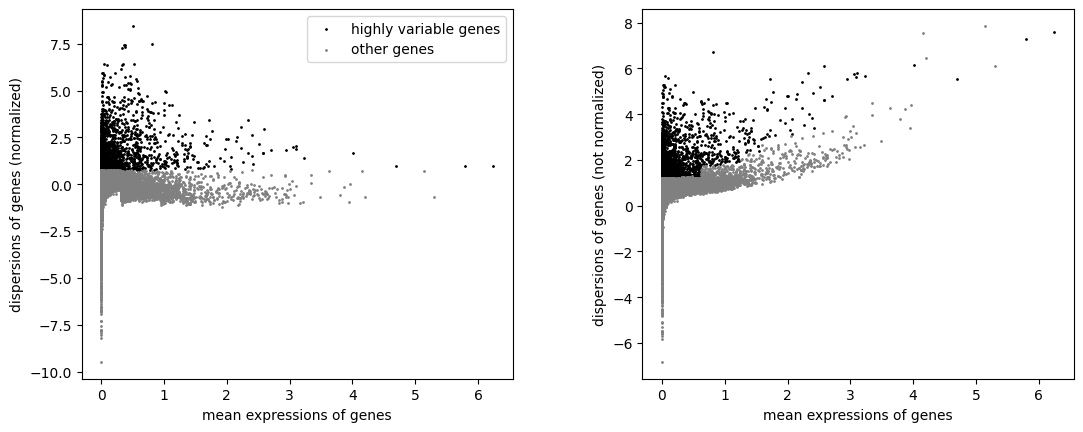

In [ ]:

sc.pl.highly_variable_genes(adata)
# fin de ton notebook preprocessing
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="batch")
adata_hvg = adata[:, adata.var["highly_variable"]].copy()
#enregistrement du fichier dans le drive
adata_hvg.write_h5ad(f"{DATA_DIR}/preprocessed.h5ad")

In [ ]:
adata.var['highly_variable']


A1BG      False
A1CF      False
A2M        True
A2ML1     False
A4GALT    False
          ...  
ZXDC      False
ZYG11B    False
ZYX       False
ZZEF1     False
ZZZ3      False
Name: highly_variable, Length: 18268, dtype: bool

In [ ]:
sc.pp.pca(adata)


In [ ]:
sc.pl.pca(adata)


In [ ]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)


In [ ]:


sc.pl.pca(
    adata,
    color=["batch", "batch", "size_factor", "n_count"],
    dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)],
    ncols=2,
    size=2,
)

